In [ ]:
##Retail Analytics & AI-Powered SalesForecasting System (major_project unlox)
##Name: R Darshan BBA Fintech and banking student

In [1]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn plotly streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
##Import libraries

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
##Load your dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Check the current Jupyter folder
print("Current folder:", Path.cwd())

# Find CSV files in the current folder
csv_files = list(Path.cwd().glob("*.csv"))
print("CSV files found:", [f.name for f in csv_files])

# Load the retail dataset
matches = [
    f for f in csv_files
    if "Retail_Sales_Data_Unlox" in f.name
]

if not matches:
    raise FileNotFoundError(
        "Retail dataset not found. Put your CSV in the same folder as this notebook."
    )

df = pd.read_csv(matches[0])

# Prepare the Date column
df.columns = df.columns.str.strip()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Current folder: C:\Users\R Darshan\major_project.R.Darshan
CSV files found: ['Retail_Sales_Data_Unlox (1).csv']

Dataset loaded successfully!
Shape: (73000, 19)
Columns: ['Date', 'Store_ID', 'Store_Location', 'Product_ID', 'Product_Category', 'Product_Subcategory', 'Brand', 'Unit_Price', 'Units_Sold', 'Total_Sales', 'Discount_Percentage', 'Revenue', 'Customer_Type', 'Payment_Mode', 'Promotion_Applied', 'Stock_On_Hand', 'Store_Rating', 'Region', 'Holiday_Flag']


,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Customer_Type,Payment_Mode,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag
0,2023-04-13,STR_104,Chennai,PRD_072,Sports,Athletics,Reebok,29973.06,39,1168949.34,5,1.110502e+06,Returning,Debit Card,Yes,422,4.4,South,0
1,2024-10-25,STR_103,Delhi,PRD_492,Sports,Outdoor,Yonex,46933.78,2,93867.56,15,7.978743e+04,Returning,UPI,No,302,4.1,North,0
2,2023-02-28,STR_107,Kolkata,PRD_958,Groceries,Household,Nestle,39280.28,44,1728332.32,15,1.469082e+06,Returning,Cash,No,184,3.8,East,0
3,2023-06-16,STR_102,Bangalore,PRD_014,Home Appliances,Kitchen,Whirlpool,40439.03,9,363951.27,5,3.457537e+05,New,UPI,Yes,493,3.7,South,0
4,2024-05-23,STR_108,Ahmedabad,PRD_932,Fashion,Women Clothing,Puma,9193.58,4,36774.32,5,3.493560e+04,Returning,Credit Card,No,359,3.5,West,0


In [ ]:
##Check the dataset

In [7]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe(include="all").T)

Column names:
['Date', 'Store_ID', 'Store_Location', 'Product_ID', 'Product_Category', 'Product_Subcategory', 'Brand', 'Unit_Price', 'Units_Sold', 'Total_Sales', 'Discount_Percentage', 'Revenue', 'Customer_Type', 'Payment_Mode', 'Promotion_Applied', 'Stock_On_Hand', 'Store_Rating', 'Region', 'Holiday_Flag']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73000 entries, 0 to 72999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 73000 non-null  object 
 1   Store_ID             73000 non-null  object 
 2   Store_Location       73000 non-null  object 
 3   Product_ID           73000 non-null  object 
 4   Product_Category     73000 non-null  object 
 5   Product_Subcategory  73000 non-null  object 
 6   Brand                73000 non-null  object 
 7   Unit_Price           73000 non-null  float64
 8   Units_Sold           73000 non-null  int64  
 9   Total

Date                   0
Store_ID               0
Store_Location         0
Product_ID             0
Product_Category       0
Product_Subcategory    0
Brand                  0
Unit_Price             0
Units_Sold             0
Total_Sales            0
Discount_Percentage    0
Revenue                0
Customer_Type          0
Payment_Mode           0
Promotion_Applied      0
Stock_On_Hand          0
Store_Rating           0
Region                 0
Holiday_Flag           0
dtype: int64


Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,73000,731,2023-01-19,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_ID,73000,8,STR_105,9254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location,73000,8,Pune,9254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_ID,73000,998,PRD_713,106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Category,73000,5,Sports,14711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Subcategory,73000,15,Laptops,4989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,73000,20,OnePlus,3714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unit_Price,73000.0,NaN,NaN,NaN,25110.208554,14393.607981,100.11,12728.855,25071.8,37557.3375,49999.85
Units_Sold,73000.0,NaN,NaN,NaN,24.894589,14.134824,1.0,13.0,25.0,37.0,49.0
Total_Sales,73000.0,NaN,NaN,NaN,626138.239282,544854.836919,144.7,175985.2325,471357.72,953986.38,2447350.08


In [ ]:
##Clean the data

In [22]:
df.columns = df.columns.str.strip()

required_columns = ["Date", "Store_ID", "Units_Sold", "Revenue"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns missing from dataset: {missing_columns}")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"]).drop_duplicates().copy()

numeric_columns = [
    "Units_Sold", "Unit_Price", "Total_Sales",
    "Discount_Percentage", "Revenue", "Stock_On_Hand", "Store_Rating"
]
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Units_Sold", "Revenue"]).copy()
df["Units_Sold"] = df["Units_Sold"].clip(lower=0)
df["Revenue"] = df["Revenue"].clip(lower=0)

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek

print("Cleaning completed!")
print("Final dataset shape:", df.shape)
print("Missing values remaining in required fields:",
      df[["Date", "Store_ID", "Units_Sold", "Revenue"]].isna().sum().sum())
display(df.head())

Cleaning completed!
Final dataset shape: (73000, 24)
Missing values remaining in required fields: 0


,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,...,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag,Year,Month,Month_Name,Day,DayOfWeek
0,2023-04-13,STR_104,Chennai,PRD_072,Sports,Athletics,Reebok,29973.06,39,1168949.34,...,Yes,422,4.4,South,0,2023,4,April,13,3
1,2024-10-25,STR_103,Delhi,PRD_492,Sports,Outdoor,Yonex,46933.78,2,93867.56,...,No,302,4.1,North,0,2024,10,October,25,4
2,2023-02-28,STR_107,Kolkata,PRD_958,Groceries,Household,Nestle,39280.28,44,1728332.32,...,No,184,3.8,East,0,2023,2,February,28,1
3,2023-06-16,STR_102,Bangalore,PRD_014,Home Appliances,Kitchen,Whirlpool,40439.03,9,363951.27,...,Yes,493,3.7,South,0,2023,6,June,16,4
4,2024-05-23,STR_108,Ahmedabad,PRD_932,Fashion,Women Clothing,Puma,9193.58,4,36774.32,...,No,359,3.5,West,0,2024,5,May,23,3


In [ ]:
##Sales analysis

In [9]:
print("Total revenue:", df["Revenue"].sum())
print("Total units sold:", df["Units_Sold"].sum())
print("Average revenue:", df["Revenue"].mean())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Total revenue: 41133782864.74899
Total units sold: 1817305
Average revenue: 563476.4775993013
Date range: 2023-01-01 00:00:00 to 2024-12-31 00:00:00


In [ ]:
##Monthly revenue trend

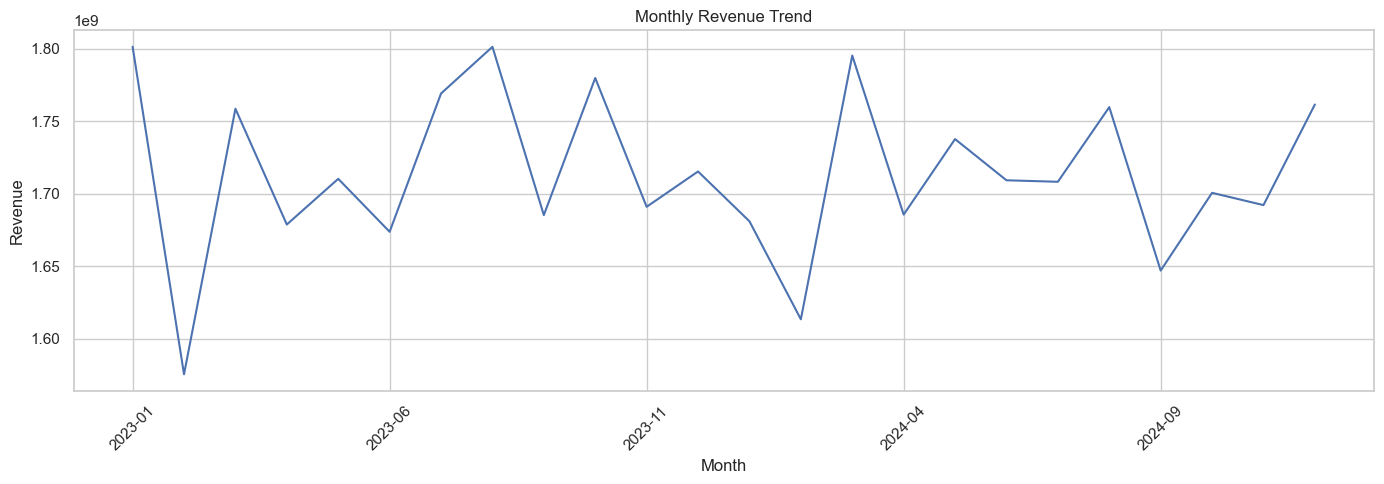

In [10]:
monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Revenue"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(14, 5))
monthly_sales.plot()
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Seasonal Sales Analysis

Year,2023,2024
Jan,1.801385e+09,1.681103e+09
Feb,1.575642e+09,1.613559e+09
Mar,1.758672e+09,1.795332e+09
Apr,1.678882e+09,1.685703e+09
May,1.710369e+09,1.737768e+09
Jun,1.673871e+09,1.709369e+09
Jul,1.769177e+09,1.708338e+09
Aug,1.801351e+09,1.759781e+09
Sep,1.685368e+09,1.647125e+09
Oct,1.779866e+09,1.700723e+09


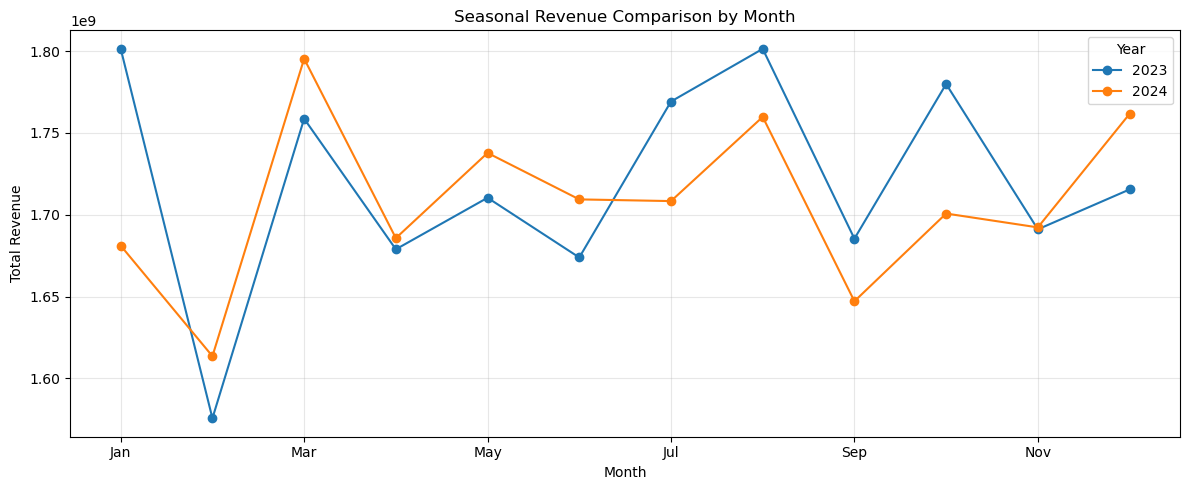

Highest revenue month: August
Revenue: 3,561,132,585.47


In [14]:
# Seasonal Sales Analysis
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()

# Compare revenue by month across years
seasonal_sales = df.pivot_table(
    index="Month",
    columns="Year",
    values="Revenue",
    aggfunc="sum"
)

seasonal_sales.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

display(seasonal_sales)

seasonal_sales.plot(
    kind="line",
    marker="o",
    figsize=(12, 5)
)

plt.title("Seasonal Revenue Comparison by Month")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Identify the strongest revenue month overall
monthly_pattern = df.groupby("Month")["Revenue"].sum()
best_month = monthly_pattern.idxmax()

print("Highest revenue month:", pd.Timestamp(
    year=2024, month=int(best_month), day=1
).strftime("%B"))
print("Revenue:", f"{monthly_pattern.max():,.2f}")


In [ ]:
##Sales by store and product category

Store_ID
STR_103    5.223064e+09
STR_102    5.186277e+09
STR_101    5.169675e+09
STR_104    5.165937e+09
STR_105    5.161899e+09
STR_107    5.107832e+09
STR_108    5.078322e+09
STR_106    5.040776e+09
Name: Revenue, dtype: float64

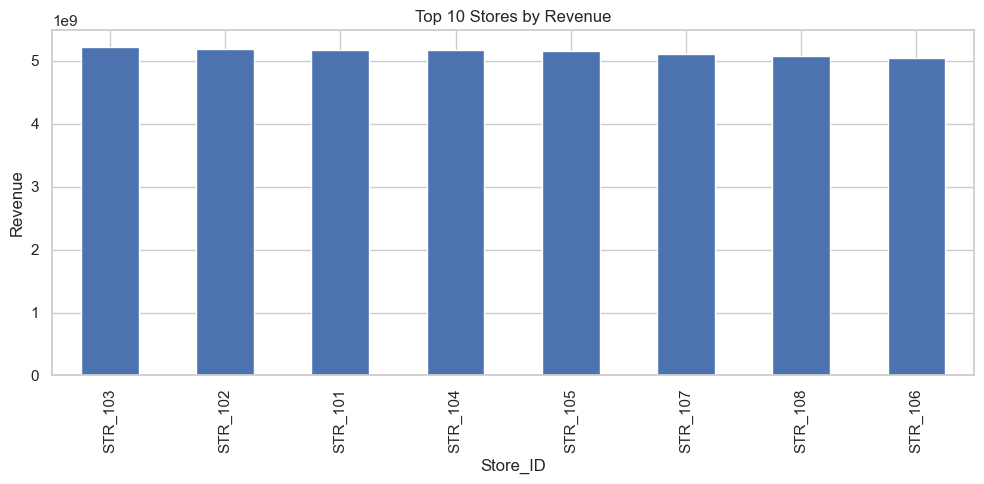

Product_Category
Electronics        8.318539e+09
Home Appliances    8.262751e+09
Fashion            8.215645e+09
Groceries          8.170528e+09
Sports             8.166319e+09
Name: Revenue, dtype: float64

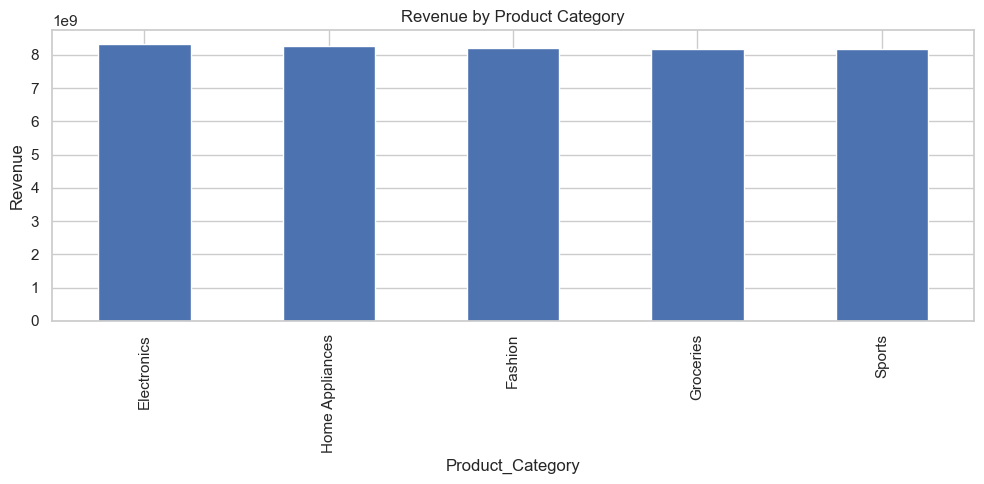

In [11]:
if "Store_ID" in df.columns:
    store_sales = df.groupby("Store_ID")["Revenue"].sum().sort_values(ascending=False)
    display(store_sales.head(10))

    store_sales.head(10).plot(kind="bar", figsize=(10, 5))
    plt.title("Top 10 Stores by Revenue")
    plt.ylabel("Revenue")
    plt.tight_layout()
    plt.show()

if "Product_Category" in df.columns:
    category_sales = df.groupby("Product_Category")["Revenue"].sum().sort_values(ascending=False)
    display(category_sales)

    category_sales.plot(kind="bar", figsize=(10, 5))
    plt.title("Revenue by Product Category")
    plt.ylabel("Revenue")
    plt.tight_layout()
    plt.show()

In [ ]:
##Find sales patterns

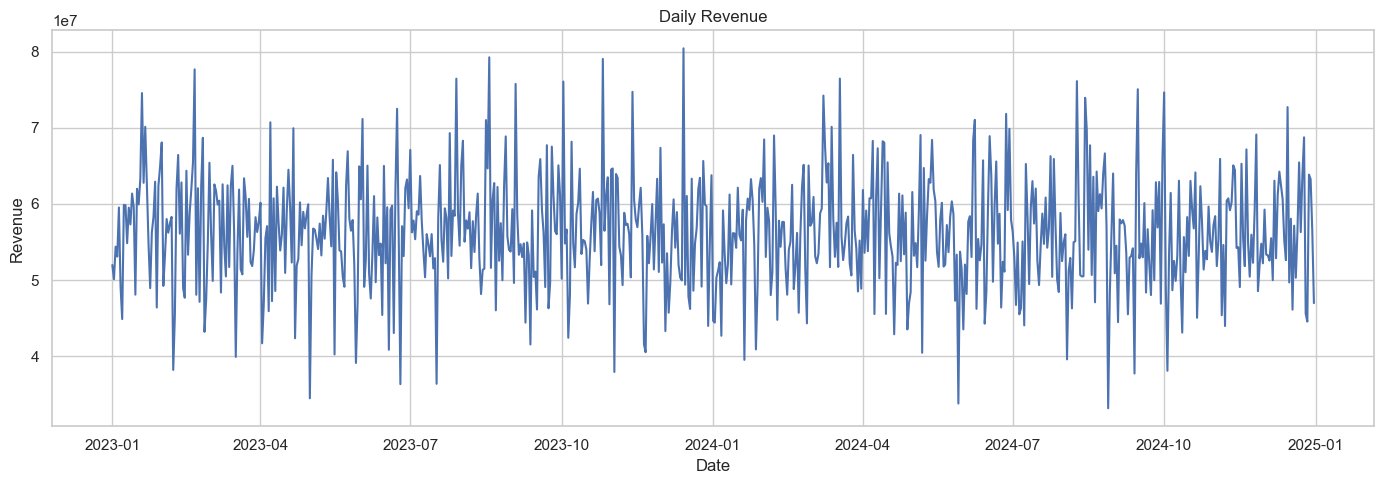

Highest revenue day: 2023-12-14 00:00:00
Highest revenue: 80450822.0845
Lowest revenue day: 2024-08-28 00:00:00
Lowest revenue: 33158280.613


In [12]:
daily_sales = df.groupby("Date")["Revenue"].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

print("Highest revenue day:", daily_sales.idxmax())
print("Highest revenue:", daily_sales.max())
print("Lowest revenue day:", daily_sales.idxmin())
print("Lowest revenue:", daily_sales.min())

In [ ]:
### Daily revenue forecasting: chronological evaluation + future forecast

In [17]:
# Ensure forecasting dependencies are available even if the library-import cell was skipped.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error


Model comparison (lower MAE/RMSE is better):


,Model,MAE,RMSE
0,Ridge Regression,5741963.02,7309100.22
1,Previous-Day Baseline,8287969.11,10390704.13


Chronological holdout MAE: 5,741,963.02
Chronological holdout RMSE: 7,309,100.22


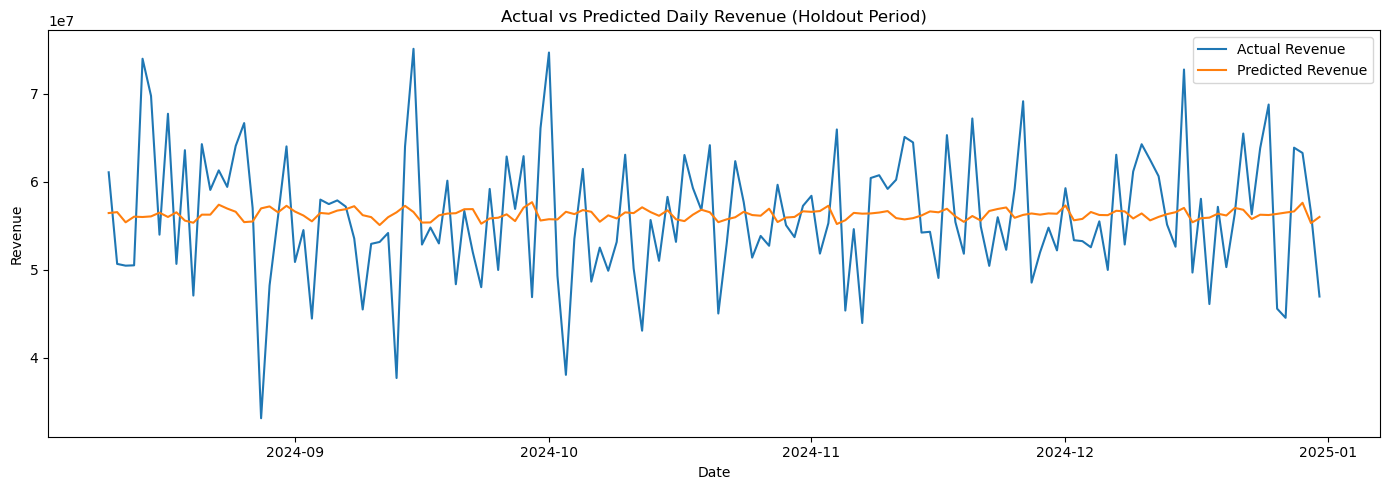

Forecast horizon: next 30 days


,Date,Forecast_Revenue
0,2025-01-01,5.589080e+07
1,2025-01-02,5.650927e+07
2,2025-01-03,5.652011e+07
3,2025-01-04,5.677571e+07
4,2025-01-05,5.725061e+07
5,2025-01-06,5.577571e+07
6,2025-01-07,5.627880e+07
7,2025-01-08,5.656726e+07
8,2025-01-09,5.609296e+07
9,2025-01-10,5.627450e+07


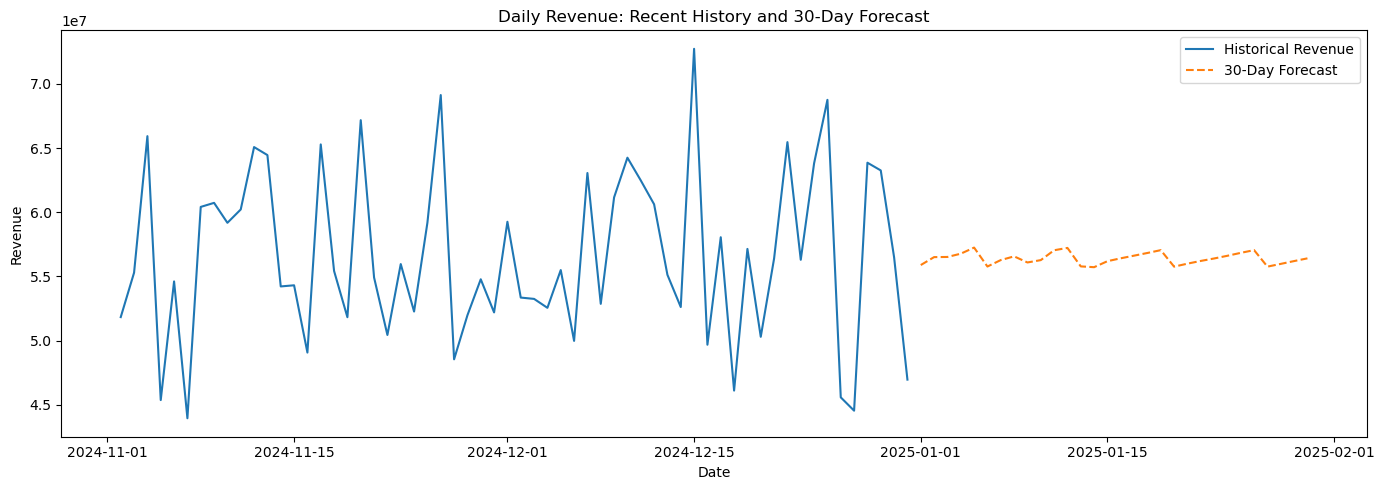

In [18]:
daily = (
    df.groupby("Date")["Revenue"]
    .sum()
    .sort_index()
    .asfreq("D", fill_value=0)
)

data = pd.DataFrame({"Revenue": daily})
data["Lag_1"] = data["Revenue"].shift(1)
data["Lag_7"] = data["Revenue"].shift(7)
data["Lag_14"] = data["Revenue"].shift(14)
data["DayOfWeek"] = data.index.dayofweek
data["Month"] = data.index.month
data = data.dropna()

features = ["Lag_1", "Lag_7", "Lag_14", "DayOfWeek", "Month"]
split = int(len(data) * 0.8)
train = data.iloc[:split].copy()
test = data.iloc[split:].copy()

if len(train) == 0 or len(test) == 0:
    raise ValueError("Not enough daily data to create train and test periods.")

model = Ridge(alpha=1.0)
model.fit(train[features], train["Revenue"])
predictions = model.predict(test[features])

# Compare Ridge Regression with a simple Previous-Day Baseline
# This is inside the forecasting cell so it runs after `test` and `predictions` are created.
baseline_predictions = test["Lag_1"]

comparison = pd.DataFrame({
    "Model": ["Ridge Regression", "Previous-Day Baseline"],
    "MAE": [
        mean_absolute_error(test["Revenue"], predictions),
        mean_absolute_error(test["Revenue"], baseline_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(test["Revenue"], predictions)),
        np.sqrt(mean_squared_error(test["Revenue"], baseline_predictions))
    ]
})

print("\nModel comparison (lower MAE/RMSE is better):")
display(comparison.round(2))


mae = mean_absolute_error(test["Revenue"], predictions)
rmse = np.sqrt(mean_squared_error(test["Revenue"], predictions))
print(f"Chronological holdout MAE: {mae:,.2f}")
print(f"Chronological holdout RMSE: {rmse:,.2f}")

plt.figure(figsize=(14, 5))
plt.plot(test.index, test["Revenue"], label="Actual Revenue")
plt.plot(test.index, predictions, label="Predicted Revenue")
plt.title("Actual vs Predicted Daily Revenue (Holdout Period)")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()

# Refit on all observed history, then forecast forward recursively.
future_days = 30
final_model = Ridge(alpha=1.0)
final_model.fit(data[features], data["Revenue"])

history = list(daily.astype(float).values)
last_date = daily.index.max()
future_dates = pd.date_range(last_date + pd.Timedelta(days=1),
                             periods=future_days, freq="D")
future_values = []

for forecast_date in future_dates:
    lag_1 = history[-1]
    lag_7 = history[-7] if len(history) >= 7 else history[-1]
    lag_14 = history[-14] if len(history) >= 14 else history[-1]
    row = pd.DataFrame([{
        "Lag_1": lag_1,
        "Lag_7": lag_7,
        "Lag_14": lag_14,
        "DayOfWeek": forecast_date.dayofweek,
        "Month": forecast_date.month
    }], columns=features)
    predicted_revenue = max(0.0, float(final_model.predict(row)[0]))
    future_values.append(predicted_revenue)
    history.append(predicted_revenue)

future_forecast = pd.DataFrame({
    "Date": future_dates,
    "Forecast_Revenue": future_values
})

print(f"Forecast horizon: next {future_days} days")
display(future_forecast.head(10))

plt.figure(figsize=(14, 5))
plt.plot(daily.index[-60:], daily.values[-60:], label="Historical Revenue")
plt.plot(future_forecast["Date"], future_forecast["Forecast_Revenue"],
         label="30-Day Forecast", linestyle="--")
plt.title("Daily Revenue: Recent History and 30-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
##Store segmentation (stores by sales performance)

,Total_Revenue,Average_Revenue,Total_Units,Segment
Store_ID,,,,
STR_103,5.223064e+09,569395.428301,229475,1
STR_102,5.186277e+09,565323.371031,228384,1
STR_101,5.169675e+09,571929.999654,226670,1
STR_104,5.165937e+09,562370.724768,228580,0
STR_105,5.161899e+09,557801.889115,227715,0
STR_107,5.107832e+09,559088.474353,229403,0
STR_108,5.078322e+09,562757.310450,223994,2
STR_106,5.040776e+09,559216.363151,223084,2


,Store_Count,Average_Total_Revenue,Average_Units_Sold
Segment,,,
0,3,5.145223e+09,228566.000000
1,3,5.193005e+09,228176.333333
2,2,5.059549e+09,223539.000000


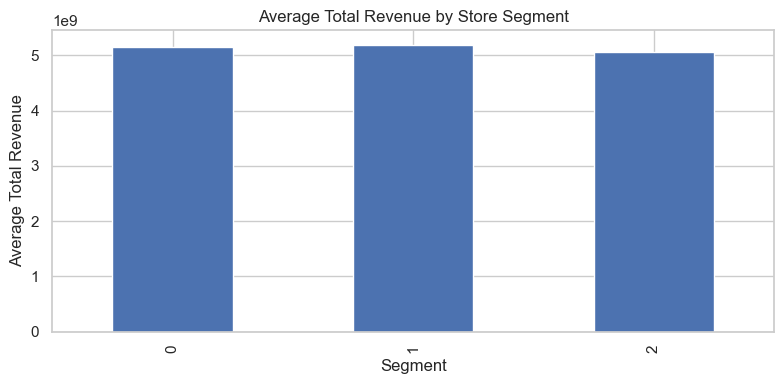

In [24]:
store_features = pd.DataFrame()

if "Store_ID" in df.columns:
    store_features = df.groupby("Store_ID").agg(
        Total_Revenue=("Revenue", "sum"),
        Average_Revenue=("Revenue", "mean"),
        Total_Units=("Units_Sold", "sum")
    )

    if len(store_features) >= 2:
        scaler = StandardScaler()
        scaled = scaler.fit_transform(store_features)

        k = min(3, len(store_features))
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        store_features["Segment"] = kmeans.fit_predict(scaled)

        display(store_features.sort_values("Total_Revenue", ascending=False))

        segment_summary = store_features.groupby("Segment").agg(
            Store_Count=("Total_Revenue", "size"),
            Average_Total_Revenue=("Total_Revenue", "mean"),
            Average_Units_Sold=("Total_Units", "mean")
        )
        display(segment_summary)

        store_features.groupby("Segment")["Total_Revenue"].mean().plot(
            kind="bar", figsize=(8, 4)
        )
        plt.title("Average Total Revenue by Store Segment")
        plt.xlabel("Segment")
        plt.ylabel("Average Total Revenue")
        plt.tight_layout()
        plt.show()
    else:
        print("At least two stores are needed for segmentation.")


In [ ]:
# GROWTH DRIVERS AND BUSINESS RECOMMENDATIONS

Top 10 stores by revenue:


,Store_ID,Total_Revenue,Units_Sold,Revenue_Share_Percent
2,STR_103,5.223064e+09,229475,12.70
1,STR_102,5.186277e+09,228384,12.61
0,STR_101,5.169675e+09,226670,12.57
3,STR_104,5.165937e+09,228580,12.56
4,STR_105,5.161899e+09,227715,12.55
6,STR_107,5.107832e+09,229403,12.42
7,STR_108,5.078322e+09,223994,12.35
5,STR_106,5.040776e+09,223084,12.25


Revenue by product category:


,Product_Category,Total_Revenue,Units_Sold,Revenue_Share_Percent
0,Electronics,8.318539e+09,367921,20.22
3,Home Appliances,8.262751e+09,365113,20.09
1,Fashion,8.215645e+09,361431,19.97
2,Groceries,8.170528e+09,359711,19.86
4,Sports,8.166319e+09,363129,19.85


Latest monthly revenue and change:


,Revenue,Previous_Month_Revenue,MoM_Change_Percent
Date,,,
2024-01-01,1.681103e+09,1.715440e+09,-2.00
2024-02-01,1.613559e+09,1.681103e+09,-4.02
2024-03-01,1.795332e+09,1.613559e+09,11.27
2024-04-01,1.685703e+09,1.795332e+09,-6.11
2024-05-01,1.737768e+09,1.685703e+09,3.09
2024-06-01,1.709369e+09,1.737768e+09,-1.63
2024-07-01,1.708338e+09,1.709369e+09,-0.06
2024-08-01,1.759781e+09,1.708338e+09,3.01
2024-09-01,1.647125e+09,1.759781e+09,-6.40


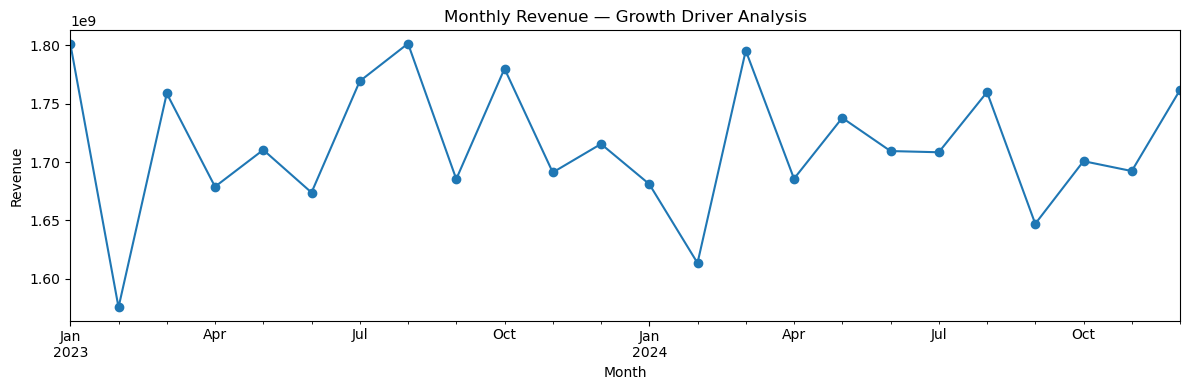


BUSINESS RECOMMENDATIONS
1. Review the practices and product mix of top-revenue store STR_103 (revenue 5,223,064,263.80; 12.7% of total) to identify practices that may be transferable to other stores.
2. Investigate operational, location, stock, and customer-mix differences at STR_106, the lowest-revenue store, before deciding on corrective action.
3. Prioritize availability monitoring for Electronics, the top-revenue category (20.2% of total revenue), while checking stock levels and margins.
4. Investigate the causes of the strongest monthly increase (March 2023, 11.6%) and the sharpest decline (February 2023, -12.5%). Check promotions, holidays, stock availability, and product mix; the data alone cannot prove causation.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Confirm that the expected columns are available before analysis.
required_for_drivers = ["Date", "Store_ID", "Revenue", "Units_Sold"]
missing_for_drivers = [c for c in required_for_drivers if c not in df.columns]
if missing_for_drivers:
    raise ValueError(f"Cannot run growth-driver analysis. Missing columns: {missing_for_drivers}")

# 1) Revenue contribution by store
store_driver = (df.groupby("Store_ID", as_index=False)
                  .agg(Total_Revenue=("Revenue", "sum"),
                       Units_Sold=("Units_Sold", "sum"))
                  .sort_values("Total_Revenue", ascending=False))
store_driver["Revenue_Share_Percent"] = 100 * store_driver["Total_Revenue"] / store_driver["Total_Revenue"].sum()
print("Top 10 stores by revenue:")
display(store_driver.head(10).round(2))

# 2) Revenue contribution by product category, if present
if "Product_Category" in df.columns:
    category_driver = (df.groupby("Product_Category", as_index=False)
                         .agg(Total_Revenue=("Revenue", "sum"),
                              Units_Sold=("Units_Sold", "sum"))
                         .sort_values("Total_Revenue", ascending=False))
    category_driver["Revenue_Share_Percent"] = 100 * category_driver["Total_Revenue"] / category_driver["Total_Revenue"].sum()
    print("Revenue by product category:")
    display(category_driver.round(2))
else:
    category_driver = pd.DataFrame()
    print("Product_Category is not available; category analysis skipped.")

# 3) Month-over-month revenue changes
monthly_driver = (df.set_index("Date")["Revenue"]
                    .resample("MS").sum()
                    .rename("Revenue").to_frame())
monthly_driver["Previous_Month_Revenue"] = monthly_driver["Revenue"].shift(1)
monthly_driver["MoM_Change_Percent"] = (
    (monthly_driver["Revenue"] - monthly_driver["Previous_Month_Revenue"])
    / monthly_driver["Previous_Month_Revenue"].replace(0, np.nan) * 100
)
print("Latest monthly revenue and change:")
display(monthly_driver.tail(12).round(2))

monthly_driver["Revenue"].plot(figsize=(12, 4), marker="o", title="Monthly Revenue — Growth Driver Analysis")
plt.ylabel("Revenue")
plt.xlabel("Month")
plt.tight_layout()
plt.show()

# 4) Data-driven recommendations. These describe patterns, not guaranteed causes.
recommendations = []
if not store_driver.empty:
    top_store = store_driver.iloc[0]
    bottom_store = store_driver.iloc[-1]
    recommendations.append(
        f"Review the practices and product mix of top-revenue store {top_store['Store_ID']} "
        f"(revenue {top_store['Total_Revenue']:,.2f}; {top_store['Revenue_Share_Percent']:.1f}% of total) "
        "to identify practices that may be transferable to other stores."
    )
    recommendations.append(
        f"Investigate operational, location, stock, and customer-mix differences at "
        f"{bottom_store['Store_ID']}, the lowest-revenue store, before deciding on corrective action."
    )
if not category_driver.empty:
    best_category = category_driver.iloc[0]
    recommendations.append(
        f"Prioritize availability monitoring for {best_category['Product_Category']}, the top-revenue category "
        f"({best_category['Revenue_Share_Percent']:.1f}% of total revenue), while checking stock levels and margins."
    )
valid_changes = monthly_driver["MoM_Change_Percent"].dropna()
if not valid_changes.empty:
    best_month = valid_changes.idxmax()
    worst_month = valid_changes.idxmin()
    recommendations.append(
        f"Investigate the causes of the strongest monthly increase ({best_month.strftime('%B %Y')}, "
        f"{valid_changes.max():.1f}%) and the sharpest decline ({worst_month.strftime('%B %Y')}, "
        f"{valid_changes.min():.1f}%). Check promotions, holidays, stock availability, and product mix; the data alone cannot prove causation."
    )
print("\nBUSINESS RECOMMENDATIONS")
for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")


In [ ]:
### Save cleaned data, trends, forecasts, and store segments

In [5]:
import os
import pandas as pd

os.makedirs("outputs", exist_ok=True)

# Always save the cleaned dataset.
df.to_csv("outputs/cleaned_retail_data.csv", index=False)

# Create monthly_sales here if its earlier analysis cell has not been run.
if "monthly_sales" not in globals():
    monthly_sales = (
        df.groupby(df["Date"].dt.to_period("M"))["Revenue"]
        .sum()
        .sort_index()
    )

monthly_sales.to_csv("outputs/monthly_revenue.csv", header=["Revenue"])

# Save the forecast only if the forecasting cell has created it.
if "future_forecast" in globals():
    future_forecast.to_csv("outputs/30_day_revenue_forecast.csv", index=False)
else:
    print("Note: 30-day forecast not saved because the forecasting cell has not run yet.")

# Save store segments only if available.
if "store_features" in globals() and not store_features.empty:
    store_features.to_csv("outputs/store_segments.csv", index=True, index_label="Store_ID")

print("Results saved in the outputs folder:")
for filename in sorted(os.listdir("outputs")):
    print("-", filename)


Note: 30-day forecast not saved because the forecasting cell has not run yet.
Results saved in the outputs folder:
- .ipynb_checkpoints
- 30_day_revenue_forecast.csv
- cleaned_retail_data.csv
- monthly_revenue.csv
- store_segments.csv


In [ ]:
# PROJECT CONCLUSION — generated from the current dataset

In [8]:
print("PROJECT: Retail Analytics & AI-Powered Sales Forecasting System")
print(" BY R Darshan BBA fintech and banking student")
print("=" * 65)
print(f"Records analyzed: {len(df):,}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Total revenue: {df['Revenue'].sum():,.2f}")
print(f"Total units sold: {df['Units_Sold'].sum():,.0f}")

if "Store_ID" in df.columns:
    store_totals = df.groupby("Store_ID")["Revenue"].sum()
    print(f"Highest-revenue store: {store_totals.idxmax()} ({store_totals.max():,.2f})")
if "Product_Category" in df.columns:
    category_totals = df.groupby("Product_Category")["Revenue"].sum()
    print(f"Highest-revenue product category: {category_totals.idxmax()} ({category_totals.max():,.2f})")
if "comparison" in globals() and {"Model", "MAE", "RMSE"}.issubset(comparison.columns):
    best_model_row = comparison.sort_values("MAE").iloc[0]
    print(f"Lowest-MAE evaluated forecast method: {best_model_row['Model']} (MAE {best_model_row['MAE']:,.2f})")
if "future_forecast" in globals() and not future_forecast.empty:
    print(f"Mean forecast revenue per day for the next {len(future_forecast)} days: {future_forecast['Forecast_Revenue'].mean():,.2f}")
if "store_features" in globals() and "Segment" in store_features.columns:
    print(f"Store segments created: {store_features['Segment'].nunique()}")

print("\nConclusion:")
print("The project combines exploratory sales analysis, seasonal pattern review, daily revenue forecasting, "
      "and store segmentation to support retail decision-making. Management should use the observed "
      "patterns and forecast as decision support, validate model performance over time, and investigate "
      "business context before acting on recommendations. Forecasts are estimates, not guarantees.")


PROJECT: Retail Analytics & AI-Powered Sales Forecasting System
 BY R Darshan BBA fintech and banking student
Records analyzed: 73,000
Date range: 2023-01-01 to 2024-12-31
Total revenue: 41,133,782,864.75
Total units sold: 1,817,305
Highest-revenue store: STR_103 (5,223,064,263.80)
Highest-revenue product category: Electronics (8,318,538,868.82)

Conclusion:
The project combines exploratory sales analysis, seasonal pattern review, daily revenue forecasting, and store segmentation to support retail decision-making. Management should use the observed patterns and forecast as decision support, validate model performance over time, and investigate business context before acting on recommendations. Forecasts are estimates, not guarantees.


In [ ]:
## Thank you 
## if u like this project just drope stare 